In [1]:
import pandas as pd

df = pd.read_csv('customer_purchase_clean.csv')
df.head()

,customer_id,age,annual_income,time_on_site_min,pages_viewed,prior_purchases,email_subscriber,device,discount_offered,purchased
0,CUST1000,56,54903,4.4,10,1,1,Mobile,0,0
1,CUST1001,46,47334,4.4,6,3,1,Desktop,0,1
2,CUST1002,32,45749,1.3,8,1,0,Desktop,0,1
3,CUST1003,60,32750,7.4,9,2,1,Mobile,0,1
4,CUST1004,25,72345,7.1,9,1,1,Mobile,1,0


In [2]:
df.shape        # (rows, columns)
df.info()       # column names, data types, non-null counts
df.describe()   # mean, std, min, max, quartiles for numeric columns

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       300 non-null    str    
 1   age               300 non-null    int64  
 2   annual_income     300 non-null    int64  
 3   time_on_site_min  300 non-null    float64
 4   pages_viewed      300 non-null    int64  
 5   prior_purchases   300 non-null    int64  
 6   email_subscriber  300 non-null    int64  
 7   device            300 non-null    str    
 8   discount_offered  300 non-null    int64  
 9   purchased         300 non-null    int64  
dtypes: float64(1), int64(7), str(2)
memory usage: 27.8 KB


,age,annual_income,time_on_site_min,pages_viewed,prior_purchases,email_subscriber,discount_offered,purchased
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,40.810000,54708.756667,8.894333,6.916667,1.323333,0.373333,0.240000,0.680000
std,13.547164,20923.384037,7.546250,2.463728,1.123832,0.484498,0.427797,0.467256
min,18.000000,15000.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,29.000000,40318.500000,3.775000,5.000000,0.750000,0.000000,0.000000,0.000000
50%,41.500000,54936.500000,7.100000,7.000000,1.000000,0.000000,0.000000,1.000000
75%,52.000000,70478.250000,11.825000,9.000000,2.000000,1.000000,0.000000,1.000000
max,64.000000,118741.000000,49.600000,13.000000,6.000000,1.000000,1.000000,1.000000


In [3]:
df.isna().sum()

customer_id         0
age                 0
annual_income       0
time_on_site_min    0
pages_viewed        0
prior_purchases     0
email_subscriber    0
device              0
discount_offered    0
purchased           0
dtype: int64

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df['purchased'].value_counts()

purchased
1    204
0     96
Name: count, dtype: int64

<Axes: xlabel='purchased'>

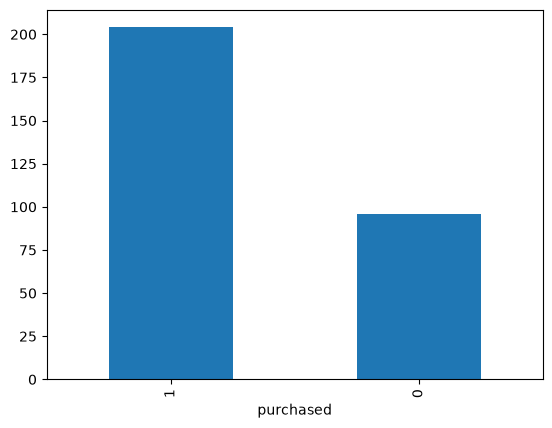

In [11]:
df['purchased'].value_counts().plot(kind='bar')

In [8]:
df_encoded = pd.get_dummies(df, columns=['device'], drop_first=True)
df_encoded.head()

,customer_id,age,annual_income,time_on_site_min,pages_viewed,prior_purchases,email_subscriber,discount_offered,purchased,device_Mobile,device_Tablet
0,CUST1000,56,54903,4.4,10,1,1,0,0,True,False
1,CUST1001,46,47334,4.4,6,3,1,0,1,False,False
2,CUST1002,32,45749,1.3,8,1,0,0,1,False,False
3,CUST1003,60,32750,7.4,9,2,1,0,1,True,False
4,CUST1004,25,72345,7.1,9,1,1,1,0,True,False


In [9]:
X = df_encoded.drop(columns=['customer_id', 'purchased'])
y = df_encoded['purchased']

print(X.shape)
print(y.shape)

(300, 9)
(300,)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(240, 9) (60, 9) (240,) (60,)


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
Standardizes the numeric feature columns (age, annual_income, time_on_site_min, 
pages_viewed, prior_purchases) so each has mean 0 and std 1 — same idea we covered 
earlier with ram_gb.

Why it matters here (and this is the key difference from your linear regression file):
Logistic regression in sklearn is trained using an iterative optimization 
algorithm (like gradient descent variants), not a plain closed-form solution.
    Unscaled features (like annual_income ranging up to 150,000 vs age ranging 18–65) 
can make this optimization slow to converge or unstable. This is exactly the case 
I mentioned earlier where scaling is not optional — it actually matters for the model 
to train properly.

In [ ]:
scaler.fit_transform(X_train) → calculates mean/std from training data,
then scales it.
scaler.transform(X_test) → uses the same mean/std learned from
training data to scale the test set (does NOT recalculate from test data).

In [12]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [16]:
print(model.coef_)        # the learned weight for each feature
print(model.intercept_ )  # the bias term (b0)

[[ 0.19105232  0.14461831  0.90377186  0.7577798   0.768592    0.11163278
   0.42585381 -0.31048833 -0.25085649]]
[1.13905107]


In [17]:
print(X_train.columns)
#above cloumn coefficents reelate it to this

Index(['age', 'annual_income', 'time_on_site_min', 'pages_viewed',
       'prior_purchases', 'email_subscriber', 'discount_offered',
       'device_Mobile', 'device_Tablet'],
      dtype='str')


In [18]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print(y_pred[:10])
print(y_prob[:10])

[1 0 0 0 0 1 1 1 1 1]
[0.92572387 0.40521444 0.49660198 0.48954259 0.2718131  0.92264092
 0.55458784 0.5079967  0.98259862 0.63551048]


In [19]:
import pandas as pd
coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': model.coef_[0]
})
print(coef_df.sort_values('coefficient', ascending=False))

            feature  coefficient
2  time_on_site_min     0.903772
4   prior_purchases     0.768592
3      pages_viewed     0.757780
6  discount_offered     0.425854
0               age     0.191052
1     annual_income     0.144618
5  email_subscriber     0.111633
8     device_Tablet    -0.250856
7     device_Mobile    -0.310488


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))